In [1]:
from src.utils import folders_creation,cracion_df_total,train_test_split_dfs
folders_creation()
df_total = cracion_df_total()
df_train, df_test = train_test_split_dfs()

Ya existe archivo total
 exist_total :True 
************************************ Comenzando split train test ************************************
Ya existe archivo train
Ya existe archivo test
exist train : True   and   exist_test :True  


# CANTIDAD DE LEIDOS POR LECTOR

In [ ]:
import matplotlib.pyplot as plt

# 1. Calcular la cantidad de libros leídos por lector
cantidad_leidos_por_lector = df_total.groupby('id_lector').size()

conteos = cantidad_leidos_por_lector.value_counts().sort_index()



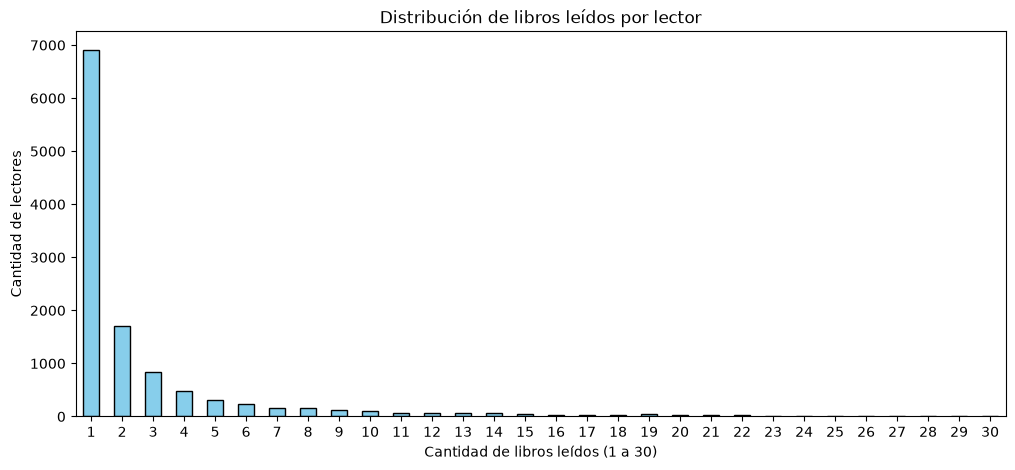

In [32]:
import matplotlib.pyplot as plt

# 1. Contar y ordenar
conteos = cantidad_leidos_por_lector.value_counts().sort_index()

# 2. Filtrar para excluir los valores atípicos extremos (ej. más de 50 libros)
conteos_filtrados = conteos[conteos.index <= 30]

# 3. Graficar con un tamaño más ancho (figsize)
conteos_filtrados.plot(kind='bar', color='skyblue', edgecolor='black', figsize=(12, 5))

plt.xlabel('Cantidad de libros leídos (1 a 30)')
plt.ylabel('Cantidad de lectores')
plt.title('Distribución de libros leídos por lector')

# Rotar las etiquetas a 0 grados para que queden horizontales
plt.xticks(rotation=0) 
plt.show()

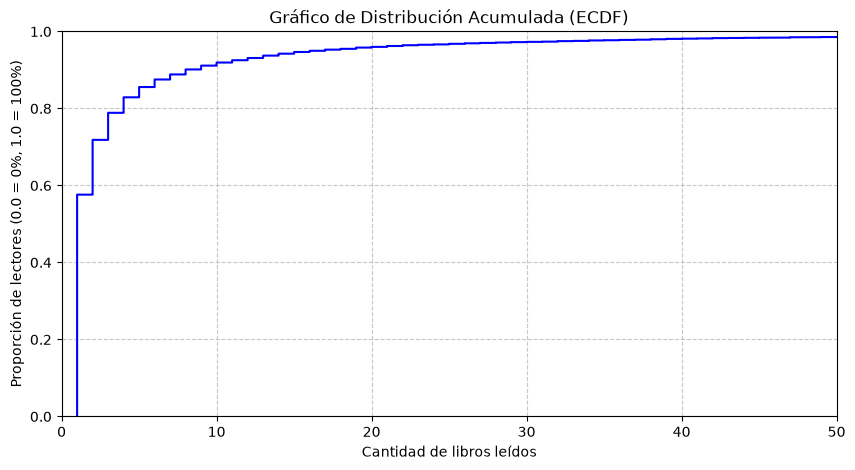

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Genera la curva de distribución acumulada
sns.ecdfplot(data=cantidad_leidos_por_lector, color='blue')

plt.xlabel('Cantidad de libros leídos')
plt.ylabel('Proporción de lectores (0.0 = 0%, 1.0 = 100%)')
plt.title('Gráfico de Distribución Acumulada (ECDF)')

# Activar la grilla ayuda mucho a leer los porcentajes contra el eje X
plt.grid(True, linestyle='--', alpha=0.7) 
plt.xlim(0, 50) # Puedes limitar el eje X si la cola es muy larga
plt.show()

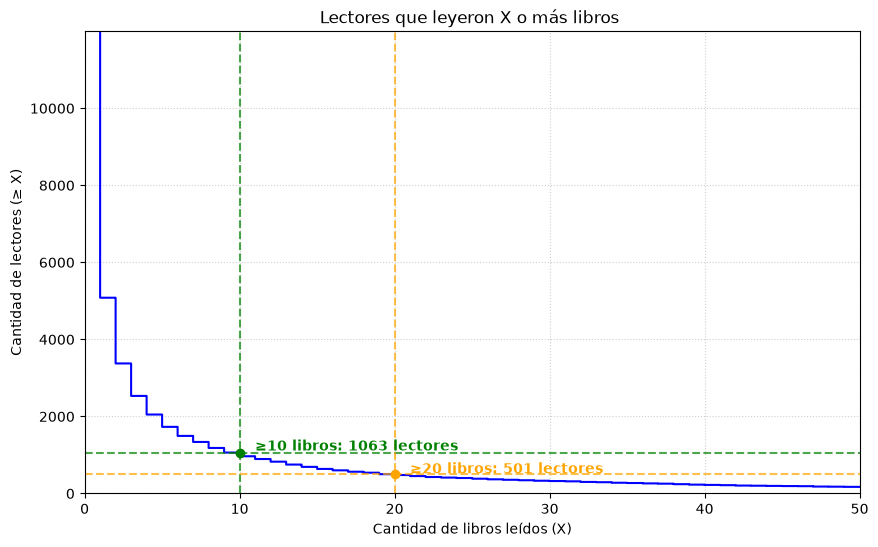

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# 1. Graficar la curva acumulada inversa
sns.ecdfplot(data=cantidad_leidos_por_lector, complementary=True, stat='count', color='blue')

# 2. Definir los puntos X que queremos marcar
puntos_x = [10,20]
colores = ['green', 'orange', 'red']

# 3. Iterar sobre cada punto para dibujar las líneas y el texto
for x, color in zip(puntos_x, colores):
    # Calcular cuántos lectores tienen >= X libros (el valor Y)
    y = (cantidad_leidos_por_lector >= x).sum()
    
    # Dibujar línea horizontal y vertical
    plt.axhline(y=y, color=color, linestyle='--', alpha=0.7)
    plt.axvline(x=x, color=color, linestyle='--', alpha=0.7)
    
    # Dibujar un punto en la intersección
    plt.plot(x, y, marker='o', color=color)
    
    # Agregar una etiqueta de texto con el número exacto
    plt.text(x + 1, y + (y * 0.05), f'≥{x} libros: {y} lectores', color=color, fontweight='bold')

# 4. Configurar el resto del gráfico
plt.xlabel('Cantidad de libros leídos (X)')
plt.ylabel('Cantidad de lectores (≥ X)')
plt.title('Lectores que leyeron X o más libros ')

plt.grid(True, linestyle=':', alpha=0.6) 
plt.xlim(0, 50) # Hacemos zoom hasta 50 libros para que se vea claro
plt.show()

In [29]:
conteos_filtrados.sum()

np.int64(501)

In [23]:
conteos.head(10)

1     6911
2     1706
3      843
4      483
5      320
6      235
7      157
8      156
9      119
10      96
Name: count, dtype: int64

In [3]:
df_train.shape

(25385, 4)

In [5]:
df_test.shape

(10020, 4)

In [8]:
df_test.id_lector.nunique()

501

In [9]:
501*20

10020

In [2]:
from src.feat_eng import pipeline_feature_engineering
df_total_feat= pipeline_feature_engineering(df_total)

=============== INICIANDO PIPELINE DE FEATURE ENGINEERING del state : entrenamiento ===============
-> Aplicando: volumen_lectura_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_crudo_por_lector para el estado : entrenamiento
-> Aplicando: desviacion_estandar_rating_por_lector para el estado : entrenamiento
-> Aplicando: genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: ratio_libros_antiguos_vs_nuevos_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_lector para el estado : entrenamiento
-> Aplicando: pct_autor_favorito_por_lector para el estado : entrenamiento
-> Aplicando: pct_genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: popularidad_count_por_libro y popularidad_rating_mean_por_libro para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_libro para el estado : entrenamiento
-> Aplicando: pct_lecturas_autor_candidato_por_par_libroylector para el estado : entrenamiento
-> 

In [4]:
import pandas as pd
pd.set_option('display.max_columns', None)

In [6]:
df_total_feat.id_libro.nunique()

19383

In [7]:
df_total_feat.ranking.nunique()

16581

In [5]:
df_total_feat.head()

,id_lector,id_libro,fecha_interaccion,rating,titulo,autor,genero_libro,anio_edicion,rating_promedio,cantidad_votos,volumenes,capitulos,ranking,en_emision,genero,vive_en,nacimiento,volumen_lectura_por_lector,rating_promedio_crudo_por_lector,desviacion_estandar_rating_por_lector,genero_favorito_por_lector,ratio_libros_antiguos_vs_nuevos_por_lector,rating_promedio_te_por_lector,pct_autor_favorito_por_lector,pct_genero_favorito_por_lector,popularidad_count_por_libro,popularidad_rating_mean_por_libro,rating_promedio_te_por_libro,pct_lecturas_autor_candidato_por_par_libroylector,pct_lecturas_genero_candidato_por_par_libroylector
0,corkboard,12,2014-09-10,9.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,?,,NaN,15,5.733333,2.6762,Drama,2.2000,6.8146,0.133333,0.466667,9,9.5,7.4992,0.0667,0.2000
1,mchensan,12,2021-02-16,10.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,?,,1997.0,9,6.611111,1.9405,Action,0.2500,7.0585,0.111111,0.888889,9,9.5,7.4992,0.1111,0.1111
2,ShibaYuko,12,2025-08-25,10.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,M,Cemetery,2006.0,9,5.944444,2.7633,Drama,0.4286,6.9568,0.111111,0.333333,9,9.5,7.4992,0.1111,0.1111
3,guiguimauve,12,2021-07-26,9.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,?,,2002.0,17,6.352941,1.8846,Comedy,17.0000,6.9396,0.058824,0.411765,9,9.5,7.4992,0.0588,0.4118
4,jjjhanghao,12,2021-03-24,10.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,F,I live with my imaginary boyfriends.,NaN,5,9.900000,0.2000,Action,0.5000,7.3900,0.200000,0.600000,9,9.5,7.4992,0.2000,0.2000


In [9]:
df_train.head()

,id_lector,id_libro,rating,fecha_interaccion
0,0Pharaoh,88502.0,10.0,2025-12-26
1,0Pharaoh,78077.0,7.5,2025-12-29
2,0Pharaoh,111112.0,4.0,2026-05-02
0,135dragon,53482.0,9.0,2021-02-12
1,135dragon,23973.0,8.0,2021-02-13


In [13]:
df_test.groupby('id_lector').size()

id_lector
0Pharaoh         10
135dragon        10
35seali          10
707hairline      10
786Cookie        10
                 ..
ysaaaa           10
yujitegal        10
zdubwilly        10
zplaguez         10
zuhakaedehara    10
Length: 1063, dtype: int64

In [3]:
df_train_features = pipeline_feature_engineering(df_train, state='entrenamiento')

=============== INICIANDO PIPELINE DE FEATURE ENGINEERING del state : entrenamiento ===============
-> Aplicando: volumen_lectura_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_crudo_por_lector para el estado : entrenamiento
-> Aplicando: desviacion_estandar_rating_por_lector para el estado : entrenamiento
-> Aplicando: genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: ratio_libros_antiguos_vs_nuevos_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_lector para el estado : entrenamiento
-> Aplicando: pct_autor_favorito_por_lector para el estado : entrenamiento
-> Aplicando: pct_genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: popularidad_count_por_libro y popularidad_rating_mean_por_libro para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_libro para el estado : entrenamiento
-> Aplicando: pct_lecturas_autor_candidato_por_par_libroylector para el estado : entrenamiento
-> 

In [4]:
from src.filtrado_colaborativo import filtrado_colaborativo
m_lectores, m_libros = filtrado_colaborativo(state='entrenamiento')

Ya existe matriz de lectores para el state: entrenamiento
Ya existe matriz de libros para el state: entrenamiento


In [5]:
m_lectores

,generolector_?,generolector_F,generolector_M,generolector_O,pais_Argentina,pais_Australia,pais_Bahamas,pais_Belgium,pais_Brasil,pais_Brazil,...,autor_mini,autor_otro,anio_edicion_1960s,anio_edicion_1970s,anio_edicion_1980s,anio_edicion_1990s,anio_edicion_2000s,anio_edicion_2010s,anio_edicion_2020s,anio_edicion_viejos
id_lector,,,,,,,,,,,,,,,,,,,,,
0Pharaoh,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.400000,0.0,0.0,0.0,0.0,0.0,0.000000,0.716667,0.0
135dragon,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.788000,0.0,0.0,0.0,0.0,0.0,0.783333,0.900000,0.0
707hairline,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.621154,0.0,0.0,0.0,0.0,0.0,0.550769,0.649333,0.0
786Cookie,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.457143,0.0,0.0,0.0,0.0,0.3,0.592857,0.350000,0.3
8dajdn1lm114gsdggg,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.700000,0.0,0.0,0.0,0.0,0.0,1.000000,0.700000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
yoohaaa,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.985000,0.0,0.0,0.0,0.0,0.0,0.981250,1.000000,0.0
ysaaaa,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.000000,0.0,0.0,0.0,0.0,0.0,1.000000,0.000000,0.0
zdubwilly,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.366667,0.0,0.0,0.0,0.0,0.3,0.000000,0.400000,0.0


In [5]:
from src.entrenar_ease import obtener_modelo_ease
modelo_ease = obtener_modelo_ease(df_train, state="entrenamiento")

-> Cargando modelo EASE desde caché: outputs/ease/modelo_ease_entrenamiento.pkl


In [6]:
from src.construccion_cache import construir_cache
cache = construir_cache(df_train_features ,modelo_lgbm_reg=None, modelo_lgbm_ranker=None,modelo_ease=modelo_ease, state='entrenamiento')


Construyendo Caché para Retrievals...
Caché  de entrenamiento construido con éxito.
